# Cascade trophique à Yellowstone : un système d'EDO raide

En 1995, des loups ont été réintroduits dans le parc de Yellowstone. En chassant les wapitis (de grands
cerfs), ils ont fait baisser la pression sur la végétation, qui a repoussé le long des rivières.
C'est l'exemple classique de **cascade trophique** : un effet domino le long de la chaîne alimentaire.

Ce projet (cours d'EDO, Polytech Nice Sophia) modélise un écosystème à 5 espèces par un système de
5 équations différentielles non linéaires, puis le résout avec des schémas numériques codés à la main.
Le point délicat est que le système est **raide**, ce qui oblige à choisir la méthode avec soin.

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

## Le modèle

L'état est $u = (V, N, D, W, B)$ : végétation (kg/km²), wapitis, cerfs, loups et ours (individus/km²).

$$\frac{dV}{dt} = r_V V\Big(1 - \frac{V}{K_V}\Big) - \frac{\alpha_N V N}{\nu_N + V} - \frac{\alpha_D V D}{\nu_D + V} - \frac{\alpha_B V B}{\nu_B + V}$$

$$\frac{dN}{dt} = r_N N\Big[1 - \Big(\frac{N}{\kappa_N(V)}\Big)^{\theta_N}\Big] - \frac{c_{WN} N W}{W + \beta N} - \frac{c_{BN} N B}{h_{BN} + N} - \delta_N N$$

$$\frac{dD}{dt} = r_D D\Big[1 - \Big(\frac{D}{\kappa_D(V)}\Big)^{\theta_D}\Big] - \frac{c_{WD} D W}{h_{WD} + D} - \frac{c_{BD} D B}{h_{BD} + D} - \delta_D D$$

$$\frac{dW}{dt} = \big[\varepsilon_1 \ln(\Phi_W + \eta) - \varepsilon_2 - m_W - \mu_W \sin^2(\pi t)\big]\, W$$

$$\frac{dB}{dt} = \Big[e_B\Big(\frac{c_{BN} N}{h_{BN} + N} + \frac{c_{BD} D}{h_{BD} + D}\Big) + \frac{e_V \alpha_B V}{\nu_B + V} - m_B\Big] B$$

En français :
- la végétation pousse de façon logistique et se fait brouter par les trois autres herbivores ou omnivores ;
- wapitis et cerfs ont une capacité d'accueil $\kappa(V) = K\,\frac{V}{V^* + V}$ qui dépend de la
  végétation disponible, et se font manger par les loups et les ours ;
- pour les loups, la prédation sur les wapitis dépend du **rapport** loups / wapitis (et pas seulement
  du nombre de wapitis), $\Phi_W$ est le nombre de proies tuées par loup, et il y a une **chasse humaine**
  saisonnière $\mu_W \sin^2(\pi t)$ ;
- les ours sont omnivores : ils mangent des proies **et** de la végétation.

In [2]:
PARAMS = dict(
    r_V=1.20, K_V=500.0, alpha_N=15.0, nu_N=200.0, alpha_D=8.0, nu_D=100.0, alpha_B=3.0, nu_B=120.0,
    r_N=0.30, K_N=7.0, V_star=70.0, theta_N=4.0, c_WN=7.5, beta=0.5, c_BN=0.5, h_BN=3.0, delta_N=0.05,
    r_D=0.50, K_D=4.0, V_2star=50.0, theta_D=2.0, c_WD=2.0, h_WD=2.0, c_BD=0.3, h_BD=1.5, delta_D=0.08,
    eps1=0.25, eps2=0.50, eta=0.01, m_W=0.15, mu_W=0.10, periode_chasse=1.0,
    e_B=0.12, e_V=0.02, m_B=0.08,
)
U0 = np.array([440.0, 4.5, 2.5, 0.04, 0.25])          # V, N, D, W, B au départ
ECHELLES = np.array([500.0, 10.0, 5.0, 0.15, 3.0])     # ordre de grandeur de chaque variable
U_MIN = ECHELLES * 1e-6                                # plancher : pas de densité négative
NOMS = ["Végétation V", "Wapitis N", "Cerfs D", "Loups W", "Ours B"]


def F(t, u, p):
    V, N, D, W, B = u
    kappa_N = p["K_N"] * V / (p["V_star"] + V)
    kappa_D = p["K_D"] * V / (p["V_2star"] + V)
    Phi_W = p["c_WN"] * N / (W + p["beta"] * N) + p["c_WD"] * D / (p["h_WD"] + D)

    dV = (p["r_V"] * V * (1 - V / p["K_V"]) - p["alpha_N"] * V * N / (p["nu_N"] + V)
          - p["alpha_D"] * V * D / (p["nu_D"] + V) - p["alpha_B"] * V * B / (p["nu_B"] + V))
    dN = (p["r_N"] * N * (1 - (N / kappa_N) ** p["theta_N"]) - p["c_WN"] * N * W / (W + p["beta"] * N)
          - p["c_BN"] * N * B / (p["h_BN"] + N) - p["delta_N"] * N)
    dD = (p["r_D"] * D * (1 - (D / kappa_D) ** p["theta_D"]) - p["c_WD"] * D * W / (p["h_WD"] + D)
          - p["c_BD"] * D * B / (p["h_BD"] + D) - p["delta_D"] * D)
    chasse = p["mu_W"] * np.sin(np.pi * t / p["periode_chasse"]) ** 2
    dW = (p["eps1"] * np.log(Phi_W + p["eta"]) - p["eps2"] - p["m_W"] - chasse) * W
    dB = (p["e_B"] * (p["c_BN"] * N / (p["h_BN"] + N) + p["c_BD"] * D / (p["h_BD"] + D))
          + p["e_V"] * p["alpha_B"] * V / (p["nu_B"] + V) - p["m_B"]) * B
    return np.array([dV, dN, dD, dW, dB])

## Pourquoi le système est raide

Il mélange des échelles de temps très différentes : la chasse change en quelques mois, alors que les
populations de loups et d'ours évoluent sur des dizaines d'années. Une méthode **explicite** (qui
calcule le futur avec la pente d'aujourd'hui) n'est stable que si le pas de temps est assez petit
devant les phénomènes les plus rapides. Sur 100 ans, ça fait beaucoup de pas. D'où l'intérêt d'une
méthode **implicite**, stable même avec de grands pas.

## Les quatre schémas

Chaque fonction fait un pas de temps $u_n \to u_{n+1}$.

- **Euler explicite** : $u_{n+1} = u_n + h\,F(t_n, u_n)$. Ordre 1, très peu stable.
- **Prédicteur-correcteur** (Heun) : une prédiction par Euler, puis une correction par la méthode des
  trapèzes. Ordre 2.
- **RK4** : une moyenne pondérée de quatre pentes. Ordre 4, très précis, mais toujours explicite.
- **Euler implicite** : $u_{n+1} = u_n + h\,F(t_{n+1}, u_{n+1})$. Ordre 1 seulement, mais
  inconditionnellement stable.

Pour Euler implicite, l'inconnue est des deux côtés de l'égalité. À chaque pas, on cherche le zéro de
$G(X) = X - u_n - h\,F(t_{n+1}, X)$ avec la **méthode de Newton** : $X \leftarrow X - J_G^{-1} G(X)$,
où $J_G = I - h\,J_F$. Le point fixe ne converge pas ici (justement à cause de la raideur).
La jacobienne $J_F$ (5 × 5) est calculée par différences finies, avec un pas adapté à l'échelle de
chaque variable : la végétation vaut environ 500 alors que les loups valent 0,04.

In [3]:
def jacobienne(t, u, p):
    eps = ECHELLES * 1e-6
    F0 = F(t, u, p)
    J = np.zeros((5, 5))
    for j in range(5):
        v = u.copy(); v[j] += eps[j]
        J[:, j] = (F(t, v, p) - F0) / eps[j]
    return J


def euler_explicite(t, u, h, p):
    return u + h * F(t, u, p)


def predicteur_correcteur(t, u, h, p):
    u_pred = u + h * F(t, u, p)
    return u + h / 2 * (F(t, u, p) + F(t + h, u_pred, p))


def rk4(t, u, h, p):
    k1 = F(t, u, p)
    k2 = F(t + h / 2, u + h / 2 * k1, p)
    k3 = F(t + h / 2, u + h / 2 * k2, p)
    k4 = F(t + h, u + h * k3, p)
    return u + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)


def euler_implicite(t, u, h, p, tol=1e-8, max_iter=50):
    x = u.copy()
    for _ in range(max_iter):
        G = x - u - h * F(t + h, x, p)
        if np.max(np.abs(G) / ECHELLES) < tol:           # tolérance relative à chaque variable
            return x
        x = x + np.linalg.solve(np.eye(5) - h * jacobienne(t + h, x, p), -G)
    print(f"Newton n'a pas convergé à t = {t + h:.2f}")
    return x


def resoudre(schema, p, u0=U0, tF=100.0, h=0.1, reintroduction=None):
    """reintroduction = (t_r, dW) : on ajoute dW loups/km² à l'instant t_r."""
    n = int(round(tF / h))
    t = h * np.arange(n + 1)
    U = np.zeros((n + 1, 5)); U[0] = u0
    for k in range(n):
        u = U[k].copy()
        if reintroduction and abs(t[k] - reintroduction[0]) < h / 2:
            u[3] += reintroduction[1]
        with np.errstate(all="ignore"):
            u_suiv = schema(t[k], u, h, p)
        if not np.all(np.isfinite(u_suiv)) or np.max(np.abs(u_suiv)) > 1e8:
            print(f"{schema.__name__} diverge à t = {t[k]:.1f} ans (h = {h})")
            return t[:k + 1], U[:k + 1]
        U[k + 1] = np.maximum(u_suiv, U_MIN)
    return t, U


def tracer(t, U, titre, t_reintro=None, ref=None):
    fig, axes = plt.subplots(5, 1, figsize=(9, 10), sharex=True)
    for i, ax in enumerate(axes):
        ax.plot(t, U[:, i], lw=2, color=f"C{i}")
        if ref is not None:
            ax.plot(ref[0], ref[1][:, i], "k--", lw=1, label="RK4, h = 0,01")
        if t_reintro is not None:
            ax.axvline(t_reintro, color="gray", ls=":")
        ax.set_ylabel(NOMS[i], fontsize=9); ax.grid(alpha=0.3)
    if ref is not None:
        axes[0].legend(fontsize=8)
    axes[-1].set_xlabel("années")
    fig.suptitle(titre)
    plt.tight_layout()
    return fig

## Scénario 1 : la dynamique de base sur 100 ans

On compare RK4 avec un petit pas ($h = 0{,}01$ an, 10 000 pas) et Euler implicite avec un pas dix fois
plus grand ($h = 0{,}1$ an).

RK4 (h = 0,01) : 0.61 s | Euler implicite (h = 0,1) : 0.15 s

Végétation V  à 100 ans : RK4 480.4933 | Euler implicite 480.4847
Wapitis N     à 100 ans : RK4   0.0000 | Euler implicite   0.0000
Cerfs D       à 100 ans : RK4   2.6610 | Euler implicite   2.6676
Loups W       à 100 ans : RK4   0.0000 | Euler implicite   0.0000
Ours B        à 100 ans : RK4   2.0373 | Euler implicite   2.0228


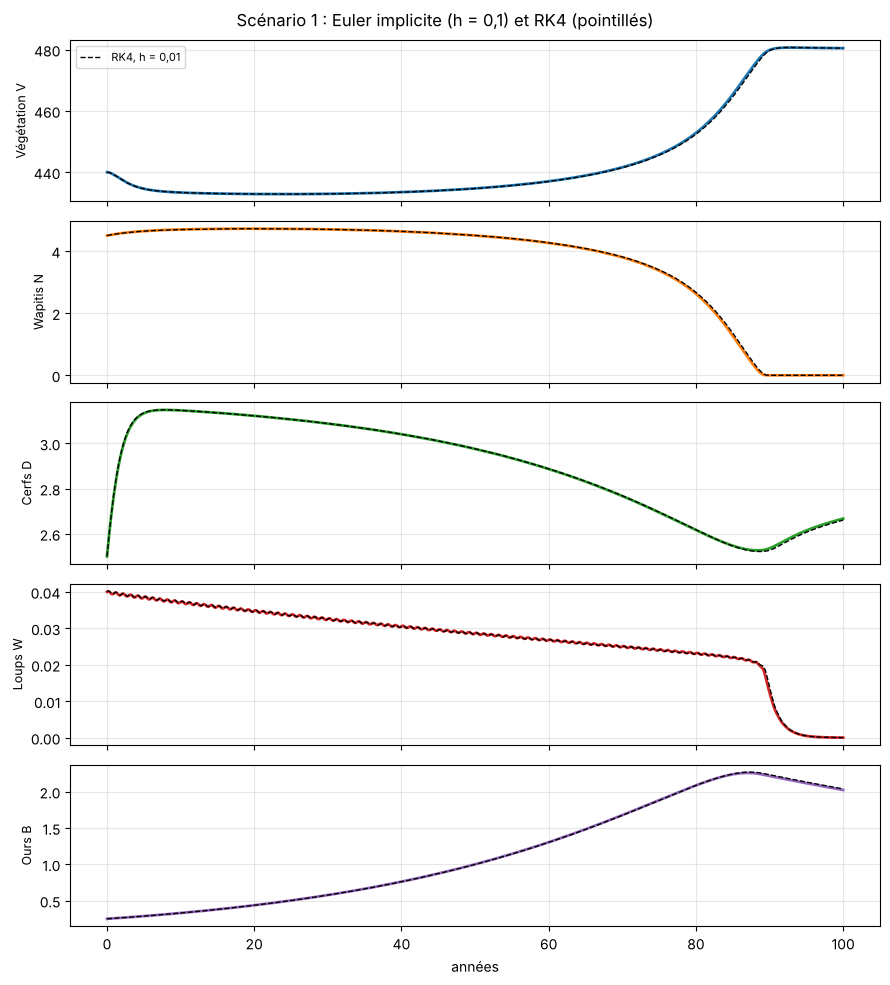

In [4]:
debut = time.time(); t_rk, U_rk = resoudre(rk4, PARAMS, h=0.01); t1 = time.time() - debut
debut = time.time(); t_ei, U_ei = resoudre(euler_implicite, PARAMS, h=0.1); t2 = time.time() - debut
print(f"RK4 (h = 0,01) : {t1:.2f} s | Euler implicite (h = 0,1) : {t2:.2f} s\n")
for i, nom in enumerate(NOMS):
    print(f"{nom:13s} à 100 ans : RK4 {U_rk[-1, i]:8.4f} | Euler implicite {U_ei[-1, i]:8.4f}")
fig = tracer(t_ei, U_ei, "Scénario 1 : Euler implicite (h = 0,1) et RK4 (pointillés)", ref=(t_rk, U_rk))
fig.savefig("figures/scenario1.png", dpi=150, bbox_inches="tight")
plt.show()

Les deux méthodes donnent la même trajectoire. Et le scénario réserve une surprise : ce n'est pas le
loup qui gagne, c'est l'**ours**.

1. Les 15 premières années, la chasse affaiblit les loups. Les cerfs, qui se reproduisent vite, montent
   jusqu'à environ 3,15 /km².
2. Les ours profitent d'une végétation abondante (ils sont omnivores) et augmentent sans arrêt :
   ils dépassent 1 /km² vers 50 ans.
3. Trop d'ours : les wapitis s'effondrent et disparaissent vers 85-90 ans. Sans leur proie principale,
   les loups s'éteignent aussi.
4. Sans gros brouteurs, la végétation remonte jusqu'à sa capacité maximale (environ 480 kg/km²).

### Et avec un grand pas ?

Même scénario, mais avec $h = 0{,}5$ an pour les quatre méthodes.

predicteur_correcteur diverge à t = 90.5 ans (h = 0.5)
rk4 diverge à t = 89.0 ans (h = 0.5)


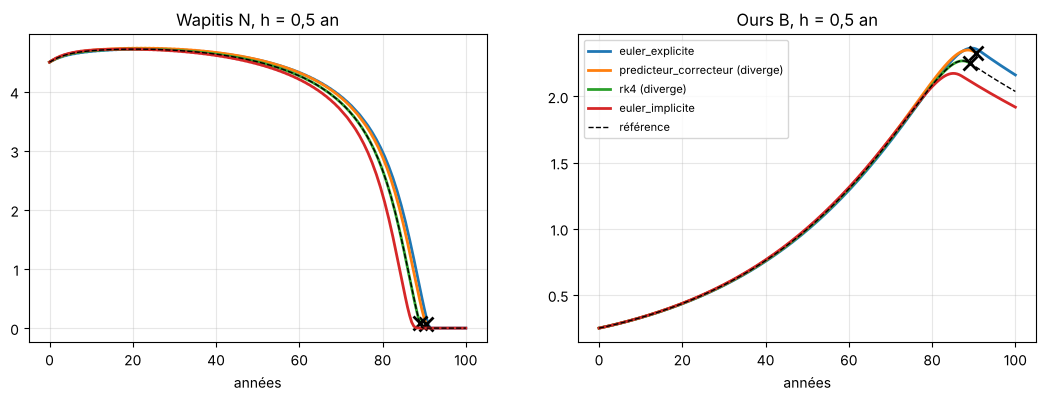

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for schema in (euler_explicite, predicteur_correcteur, rk4, euler_implicite):
    t, U = resoudre(schema, PARAMS, h=0.5)
    for ax, i in zip(axes, (1, 4)):
        ax.plot(t, U[:, i], lw=2, label=schema.__name__ + (" (diverge)" if t[-1] < 100 else ""))
        if t[-1] < 100:
            ax.plot(t[-1], U[-1, i], "kx", ms=10, mew=2)
for ax, i in zip(axes, (1, 4)):
    ax.plot(t_rk, U_rk[:, i], "k--", lw=1, label="référence")
    ax.set_title(f"{NOMS[i]}, h = 0,5 an"); ax.set_xlabel("années"); ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.show()

RK4 et le prédicteur-correcteur explosent au moment où les wapitis disparaissent, quand la dynamique
devient brutale. Euler explicite survit ici grâce au plancher qui empêche les valeurs négatives, mais
s'éloigne de la référence. Euler implicite reste stable : c'est la méthode qu'on garde pour la suite.

## Scénario 2 : Yellowstone, 50 ans sans loups puis réintroduction

Pas de chasse ($\mu_W = 0$), aucun loup au départ, et on en relâche 0,04 /km² à $t = 50$ ans.

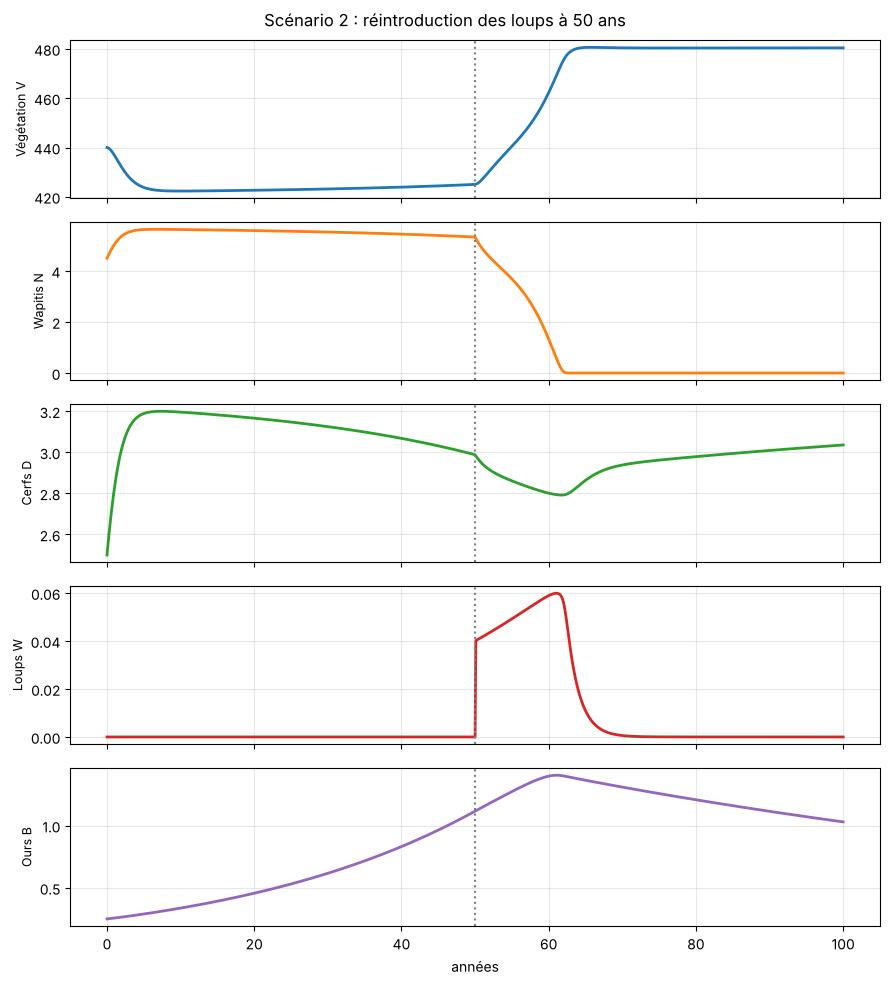

In [6]:
u0 = U0.copy(); u0[3] = 0.0
p2 = dict(PARAMS, mu_W=0.0)
t2, U2 = resoudre(euler_implicite, p2, u0=u0, reintroduction=(50, 0.04))
fig = tracer(t2, U2, "Scénario 2 : réintroduction des loups à 50 ans", t_reintro=50)
fig.savefig("figures/scenario2.png", dpi=150, bbox_inches="tight")
plt.show()

On voit la cascade trophique :
- sans loups, les wapitis atteignent un plateau (environ 5,5 /km²) et la végétation baisse vers 420 ;
- à 50 ans, les loups trouvent des proies en abondance et se multiplient, les wapitis s'effondrent en
  moins de 10 ans ;
- la **végétation repousse** jusqu'à 480. Puis les loups, qui ont épuisé leur proie principale,
  s'éteignent à leur tour.

## Scénario 3 : réintroduction avec une gestion adaptée

Dans le scénario 2, la réintroduction finit par l'extinction des wapitis puis des loups. Ici on cherche
un équilibre durable en changeant trois paramètres : des cerfs moins prolifiques ($r_D = 0{,}30$), une
mortalité des ours un peu plus forte ($m_B = 0{,}10$) et une chasse aux loups **tous les 5 ans** au
lieu de chaque année ($\sin^2(\pi t / 5)$).

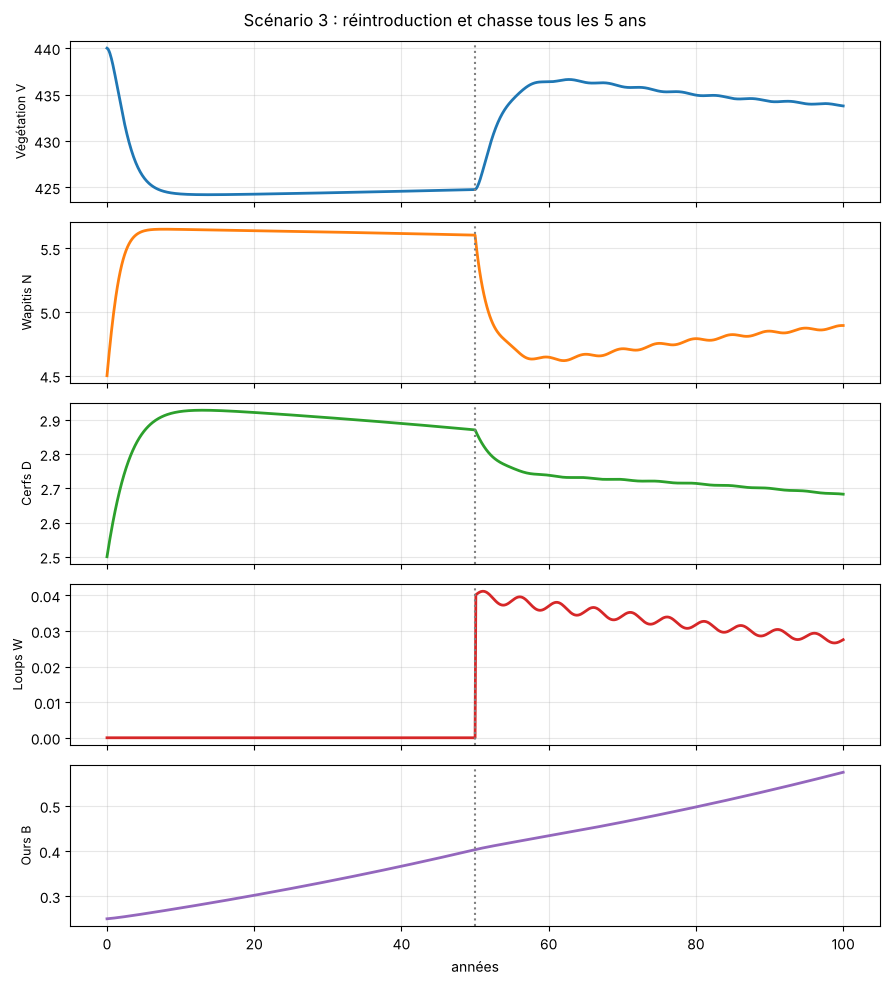

à 100 ans : V = 434, N = 4.89, W = 0.028, B = 0.57


In [7]:
p3 = dict(PARAMS, r_D=0.30, m_B=0.10, periode_chasse=5.0)
t3, U3 = resoudre(euler_implicite, p3, u0=u0, reintroduction=(50, 0.04))
fig = tracer(t3, U3, "Scénario 3 : réintroduction et chasse tous les 5 ans", t_reintro=50)
fig.savefig("figures/scenario3.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"à 100 ans : V = {U3[-1, 0]:.0f}, N = {U3[-1, 1]:.2f}, W = {U3[-1, 3]:.3f}, B = {U3[-1, 4]:.2f}")

Cette fois, après la réintroduction, les wapitis baissent d'un peu plus de 10 % puis le système trouve un
**équilibre dynamique** où loups, wapitis et végétation coexistent. Les petites ondulations de période
5 ans sur les loups et les wapitis sont la trace de la chasse espacée : entre deux campagnes, les
meutes ont le temps de se reconstituer.

## Bilan

- Côté numérique, Euler implicite avec Newton reste stable dans tous les scénarios avec un pas de
  0,1 an, là où les méthodes explicites demandent un pas beaucoup plus petit.
- Côté écologie, le modèle reproduit la cascade trophique : le retour des loups fait baisser les
  wapitis et repousser la végétation.
- Le modèle a ses limites : les ours n'ont aucun plafond de population (pas de compétition entre eux
  dans leur équation), et les équations décrivent des densités moyennes, sans notion d'espace.